# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [89]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [90]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [91]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [92]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [93]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [94]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [95]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

LabelEncoder convierte las categorías en números enteros dentro de una sola columna por ejemplo, female pasa a ser 0 y male pasa a ser 1. Y en cambio, OneHotEncoder crea una columna nueva por cada categoría usando valores de verdadero o falso, o 0 y 1, como pasa con embarked que se divide en embarked_C, embarked_Q y embarked_S. Otra diferencia es que LabelEncoder ocupa menos espacio pero puede hacer creer a un modelo que existe un orden entre las categorías, mientras que OneHotEncoder evita ese orden falso aunque aumenta la cantidad de columnas.

In [96]:
# Comparación del resultado de LabelEncoder (sex) y OneHotEncoder (embarked)
print("Mapeo de LabelEncoder en 'sex':", {k: int(v) for k, v in zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))})
print("Columnas creadas para 'embarked' con One-Hot:", list(onehot_encoder.columns))

cols_comparacion = ['sex', 'sex_label', 'embarked', 'embarked_C', 'embarked_Q', 'embarked_S']
display(data[cols_comparacion].head(10))

Mapeo de LabelEncoder en 'sex': {'female': 0, 'male': 1}
Columnas creadas para 'embarked' con One-Hot: ['embarked_C', 'embarked_Q', 'embarked_S']


,sex,sex_label,embarked,embarked_C,embarked_Q,embarked_S
0,male,1,S,False,False,True
1,female,0,C,True,False,False
2,female,0,S,False,False,True
3,female,0,S,False,False,True
4,male,1,S,False,False,True
5,male,1,Q,False,True,False
6,male,1,S,False,False,True
7,male,1,S,False,False,True
8,female,0,S,False,False,True
9,female,0,C,True,False,False


### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

En las gráficas de barras se ve que las frecuencias no cambian después de usar LabelEncoder porque sigue habiendo exactamente la misma cantidad de hombres y mujeres, solo que las etiquetas de texto cambian a números, female pasa a ser 0 y male pasa a ser 1.

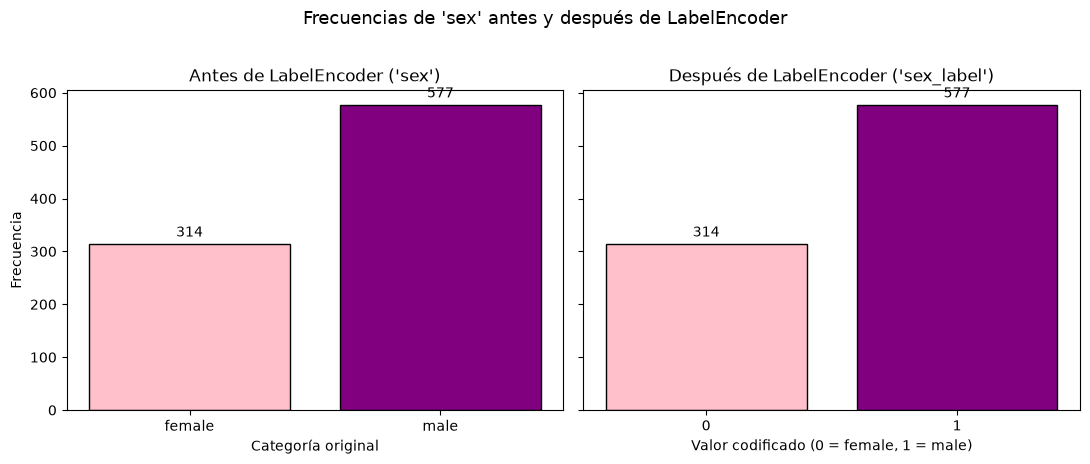

In [97]:
import matplotlib.pyplot as plt

conteo_original = data['sex'].value_counts().reindex(['female', 'male'])
conteo_codificado = data['sex_label'].value_counts().reindex([0, 1])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)

# Antes de LabelEncoder
barras_orig = axes[0].bar(conteo_original.index, conteo_original.values, color=['pink', 'purple'], edgecolor='black')
axes[0].set_title("Antes de LabelEncoder ('sex')")
axes[0].set_xlabel("Categoría original")
axes[0].set_ylabel("Frecuencia")
axes[0].bar_label(barras_orig, padding=3)

# Después de LabelEncoder
barras_cod = axes[1].bar(conteo_codificado.index.astype(str), conteo_codificado.values, color=['pink', 'purple'], edgecolor='black')
axes[1].set_title("Después de LabelEncoder ('sex_label')")
axes[1].set_xlabel("Valor codificado (0 = female, 1 = male)")
axes[1].bar_label(barras_cod, padding=3)

plt.suptitle("Frecuencias de 'sex' antes y después de LabelEncoder", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

Pues al codificar la columna class con OneHotEncoder se generan tres columnas independientes que son class_First, class_Second y class_Third, con un 1 en la clase que corresponde a cada pasajero y 0 en las demás. La ventaja frente a LabelEncoder es que cada clase se trata por separado y no se le asignan números consecutivos (0, 1 y 2) que podrían hacer que un modelo asuma distancias matemáticas fijas entre ellas, por ejemplo pensar que una clase vale el doble o triple que otra. Así el modelo puede aprender el peso real de cada clase de manera independiente.

,class,class_label,class_First,class_Second,class_Third
0,Third,2,0,0,1
1,First,0,1,0,0
2,Third,2,0,0,1
3,First,0,1,0,0
4,Third,2,0,0,1
5,Third,2,0,0,1
6,First,0,1,0,0
7,Third,2,0,0,1
8,Third,2,0,0,1
9,Second,1,0,1,0


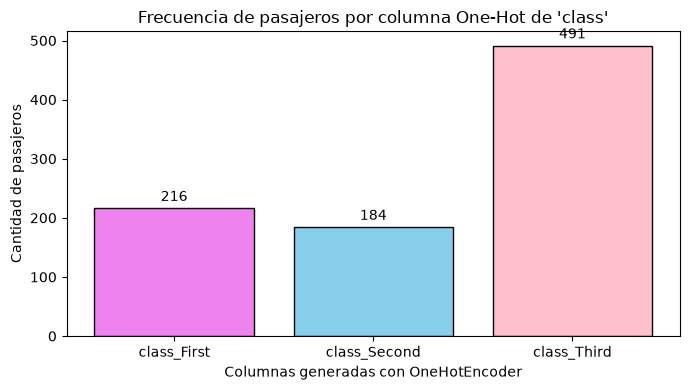

In [98]:
# Codificación de la columna 'class' usando OneHotEncoder de scikit-learn
ohe_class = OneHotEncoder(sparse_output=False, dtype=int)
class_encoded = ohe_class.fit_transform(data[['class']])
class_ohe_df = pd.DataFrame(
    class_encoded,
    columns=ohe_class.get_feature_names_out(['class']),
    index=data.index
)

# Comparación con LabelEncoder en una tabla de muestra
le_class = LabelEncoder()
comparacion_class = pd.concat([
    data[['class']],
    pd.Series(le_class.fit_transform(data['class']), name='class_label', index=data.index),
    class_ohe_df
], axis=1)

display(comparacion_class.head(10))

# Gráfica de frecuencias por columna codificada con OneHotEncoder
plt.figure(figsize=(7, 4))
conteo_class = class_ohe_df.sum()
barras = plt.bar(conteo_class.index, conteo_class.values, color=['violet', 'skyblue', 'pink'], edgecolor='black')
plt.bar_label(barras, padding=3)
plt.title("Frecuencia de pasajeros por columna One-Hot de 'class'")
plt.xlabel("Columnas generadas con OneHotEncoder")
plt.ylabel("Cantidad de pasajeros")
plt.tight_layout()
plt.show()

### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

Creo que elegiría la codificación según el tipo de cada variable categórica porque para variables con varias categorías sin un orden natural, como embarked o who, usaría OneHotEncoder para no inventar una jerarquía falsa entre ellas. Para variables binarias de solo dos opciones, como sex o alone, pues bastaría yo creo con LabelEncoder (0 y 1) porque no existe riesgo de introducir un orden equivocado y se evita crear columnas extra. Para variables que sí tienen un orden real, como class (primera, segunda y tercera clase), usaría OneHotEncoder en modelos lineales o de distancias para que cada categoría tenga su propio peso, o una codificación ordinal si se quiere conservar esa jerarquía.

In [99]:
# Resumen de las variables categóricas del dataset y la codificación recomendada
cols_cat = ['sex', 'embarked', 'class', 'who', 'alone']
resumen_codificacion = pd.DataFrame({
    'Columna': cols_cat,
    'Categorías únicas': [data[c].nunique() for c in cols_cat],
    'Valores': [list(data[c].dropna().unique()) for c in cols_cat],
    'Tipo de variable': ['Binaria', 'Nominal', 'Ordinal', 'Nominal', 'Binaria'],
    'Codificación recomendada': [
        'LabelEncoder (0 y 1)',
        'OneHotEncoder',
        'OneHotEncoder / OrdinalEncoder',
        'OneHotEncoder',
        'LabelEncoder (0 y 1)'
    ]
})
display(resumen_codificacion)

# Ejemplo de preparación de las columnas seleccionadas (categorical_cols) para un modelo
df_modelo = pd.DataFrame(index=data.index)
df_modelo['sex_encoded'] = LabelEncoder().fit_transform(data['sex'])
df_modelo = pd.concat([
    df_modelo,
    pd.get_dummies(data[['embarked', 'class']], dtype=int)
], axis=1)

print("Vista previa de variables categóricas para un modelo:")
display(df_modelo.head())

,Columna,Categorías únicas,Valores,Tipo de variable,Codificación recomendada
0,sex,2,"[male, female]",Binaria,LabelEncoder (0 y 1)
1,embarked,3,"[S, C, Q]",Nominal,OneHotEncoder
2,class,3,"[Third, First, Second]",Ordinal,OneHotEncoder / OrdinalEncoder
3,who,3,"[man, woman, child]",Nominal,OneHotEncoder
4,alone,2,"[False, True]",Binaria,LabelEncoder (0 y 1)


Vista previa de variables categóricas para un modelo:


,sex_encoded,embarked_C,embarked_Q,embarked_S,class_First,class_Second,class_Third
0,1,0,0,1,0,0,1
1,0,1,0,0,1,0,0
2,0,0,0,1,0,0,1
3,0,0,0,1,1,0,0
4,1,0,0,1,0,0,1
